<a href="https://colab.research.google.com/github/Nihat0311/Machine-Learning/blob/main/KNN_and_CLustering_task.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.cluster import AgglomerativeClustering

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.cluster import  BisectingKMeans
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import pandas as pd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingClassifier, GradientBoostingRegressor, AdaBoostClassifier, AdaBoostRegressor, BaggingClassifier, BaggingRegressor, VotingClassifier, StackingClassifier, StackingRegressor
from sklearn.svm import SVC, SVR
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, mean_squared_error, mean_absolute_error, r2_score, roc_curve
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer


In [ ]:
df=pd.read_csv('/content/simple_clustering.csv')
df

,Unnamed: 0,Driver_ID,Distance_Feature,Speeding_Feature
0,0,3423311935,71.24,28.0
1,1,3423313212,52.53,25.0
2,2,3423313724,64.54,27.0
3,3,3423311373,55.69,22.0
4,4,3423310999,54.58,25.0
...,...,...,...,...
3995,3995,3423310685,160.04,10.0
3996,3996,3423312600,176.17,5.0
3997,3997,3423312921,170.91,12.0
3998,3998,3423313630,176.14,5.0


In [ ]:
df=df.drop('Unnamed: 0',axis=1)
df

,Driver_ID,Distance_Feature,Speeding_Feature
0,3423311935,71.24,28.0
1,3423313212,52.53,25.0
2,3423313724,64.54,27.0
3,3423311373,55.69,22.0
4,3423310999,54.58,25.0
...,...,...,...
3995,3423310685,160.04,10.0
3996,3423312600,176.17,5.0
3997,3423312921,170.91,12.0
3998,3423313630,176.14,5.0


In [ ]:
df=df.drop('Driver_ID',axis=1)
df

,Distance_Feature,Speeding_Feature
0,71.24,28.0
1,52.53,25.0
2,64.54,27.0
3,55.69,22.0
4,54.58,25.0
...,...,...
3995,160.04,10.0
3996,176.17,5.0
3997,170.91,12.0
3998,176.14,5.0


In [ ]:
df.isna().sum()

,0
Distance_Feature,0
Speeding_Feature,0


In [ ]:
X=df

In [ ]:
X=df['Distance_Feature']
y=df['Speeding_Feature']

In [ ]:
st=StandardScaler()
X_scaled=st.fit_transform(df)

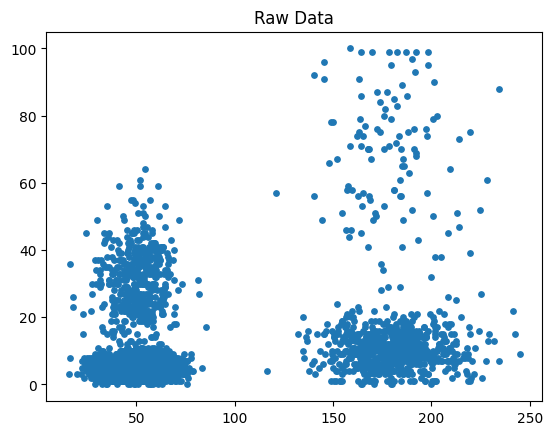

In [ ]:
plt.scatter(X,y,s=15)
plt.title("Raw Data")
plt.show()

In [ ]:
k=4
kmeans=KMeans(
    n_clusters=k,
    init='k-means++',
    n_init=10,
    random_state=42
)

In [ ]:
labels=kmeans.fit_predict(X_scaled)

In [ ]:
centers=kmeans.cluster_centers_
centers

array([[-0.48678423, -0.40249736],
       [ 1.95263225, -0.0139714 ],
       [-0.47952334,  1.57909169],
       [ 1.90400473,  4.34582367]])

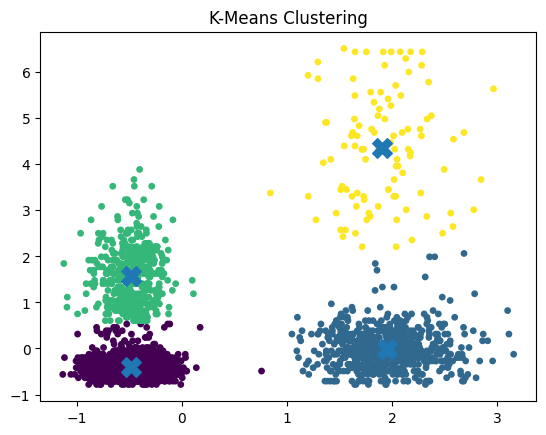

In [ ]:
plt.scatter(X_scaled[:,0],X_scaled[:,1],c=labels,s=15)
plt.scatter(centers[:,0],centers[:,1],s=200,marker='X')
plt.title("K-Means Clustering")
plt.show()

In [ ]:
kmeans.inertia_

739.1534508645556

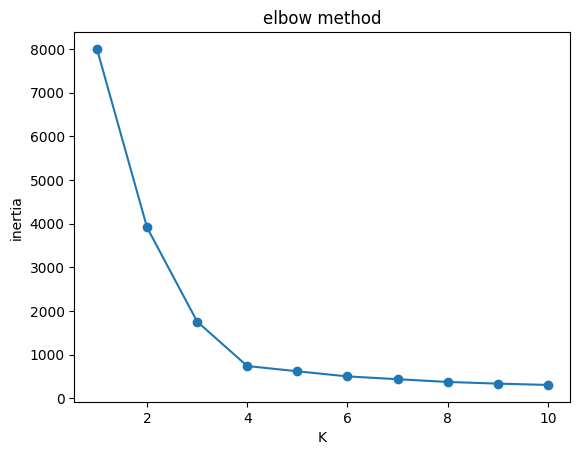

In [ ]:
inertia=[]
for i in range(1,11):
  km=KMeans(
      n_clusters=i,
      init='k-means++',
      n_init=10,
      random_state=42
  )
  km.fit(X_scaled)
  inertia.append(km.inertia_)
plt.plot(list(range(1,11)),inertia,marker='o')
plt.xlabel('K')
plt.ylabel('inertia')
plt.title('elbow method')
plt.show()

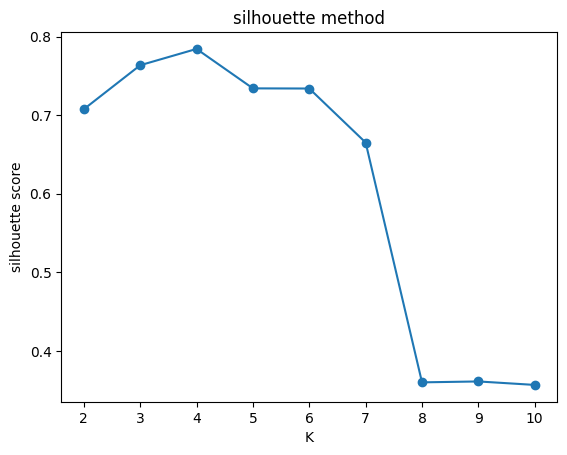

In [ ]:
sil=[]
for i in range(2,11):
  km=KMeans(
      n_clusters=i,
      init='k-means++',
      n_init=10,
      random_state=42
  )
  labels=km.fit_predict(X_scaled)
  sil.append(silhouette_score(X_scaled,labels))
plt.plot(list(range(2,11)),sil,marker='o')
plt.xlabel('K')
plt.ylabel('silhouette score')
plt.title('silhouette method')
plt.show()

In [ ]:
dbscan = DBSCAN(eps=0.825, min_samples=5)
dbscan.fit(X_scaled)

DBSCAN(eps=0.825)

In [ ]:
np.unique(labels)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=int32)

In [ ]:
for eps in [0.3,0.5,0.7,0.9,1]:
  db=DBSCAN(eps=eps,min_samples=5)
  labels=db.fit_predict(X_scaled)
  print(f"eps={eps},clusters={len(set(labels))-(1 if -1 in labels else 0)}")

eps=0.3,clusters=4
eps=0.5,clusters=2
eps=0.7,clusters=1
eps=0.9,clusters=1
eps=1,clusters=1


In [ ]:
neighbors=NearestNeighbors(n_neighbors=5)
neighbors_fit=neighbors.fit(X_scaled)

In [ ]:
distances,_=neighbors_fit.kneighbors(X_scaled)
distance=np.sort(distances[:,4])
distance=distance[:,1]
plt.plot(distance)